# MFIOP v2.0 — Fig 1b: Vibronic $\mu_{\mathrm{eff}}$ estimator (Herzberg–Teller)

**Companion to `MFIOP_v2_fig01_phase_diagram`.** That figure *draws* the vibronic band
(1.0–1.8 D) as an assumption (`axvspan`). This notebook **derives** it from
Herzberg–Teller intensity borrowing and answers the single question everything
depends on:

> How much transition dipole would the 1020 cm⁻¹ mode need to *borrow* from the
> ¹Lₐ electronic transition (35 700 cm⁻¹, μ = 2.1 D) for the dominant shoulder to
> stay resolvable, i.e. $\bar s_{\max}/\gamma > 1$ ?

No fitted spectra — just the same 5SYF mode data used in the paper, plus a
transparent HT borrowing model. Okabe–Ito style, matching the v2.0 toolkit.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# ── MFIOP v2.0 publication style (matches fig01) ──
plt.rcParams.update({
    'font.size': 11, 'font.family': 'serif',
    'axes.labelsize': 13, 'axes.titlesize': 13,
    'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 9,
    'figure.dpi': 150, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'axes.linewidth': 1.0, 'lines.linewidth': 2.0,
})
OI_BLUE='#0072B2'; OI_ORANGE='#E69F00'; OI_TEAL='#009E73'
OI_VERMILLION='#D55E00'; OI_SKY='#56B4E9'; OI_PINK='#CC79A7'
OI_YELLOW='#F0E442'; OI_BLACK='#000000'; OI_GRAY='#999999'

def add_header(fig, subtitle, fig_number=None):
    pre = f'Figure {fig_number}.  ' if fig_number is not None else ''
    fig.suptitle(f'{pre}MFIOP v2.0  |  {subtitle}',
                 fontsize=12, fontweight='bold', y=0.99)
print('Imports complete.')

Imports complete.


## 1. Reference numbers (identical to `fig01`)

The dominant modes and the maximum gap $s_{\max}$ are taken verbatim from the
5SYF analysis. At the reference electronic dipole $\mu_{ge}=2.1$ D the shoulder
is (barely) resolvable, $\bar s_{\max}/\gamma = 1.52$.


In [2]:
# --- 5SYF dominant modes (same arrays as fig01) ---
lambda_k_ref = np.array([-9.49,-1.96,-1.44,-0.34,+0.54,+1.50,+1.82,+9.38])
fk_sq        = np.array([1.390,0.005,0.793,1.103,0.105,0.061,0.078,0.005])

dominant = np.sort(lambda_k_ref[fk_sq > 0.5])
s_max_ref = float(np.max(np.diff(dominant)))      # = 8.05 cm^-1 (k=0 gap)

mu_ge     = 2.1        # D   |mu_ge| of the 1La electronic transition
gamma_ref = 5.31       # cm^-1  vibrational dephasing (lower bound)
omega_0   = 1020.0     # cm^-1  Trp IR carrier
omega_La  = 35700.0    # cm^-1  1La electronic origin
dE_ge     = omega_La - omega_0   # cm^-1  HT energy denominator

print(f'dominant modes (cm^-1): {dominant}')
print(f's_max_ref = {s_max_ref:.2f} cm^-1')
print(f's_max/gamma at mu={mu_ge} D : {s_max_ref/gamma_ref:.2f}')
print(f'HT energy gap  dE_ge = {dE_ge:.0f} cm^-1')

dominant modes (cm^-1): [-9.49 -1.44 -0.34]
s_max_ref = 8.05 cm^-1
s_max/gamma at mu=2.1 D : 1.52
HT energy gap  dE_ge = 34680 cm^-1


## 2. The scaling that makes $\mu_{\mathrm{eff}}$ decisive

Every coupling is $\lambda_k \propto \mu^2$, so the whole splitting scales as
$\mu_{\mathrm{eff}}^2$:

$$\bar s_{\max}(\mu_{\mathrm{eff}}) = s_{\max}^{\mathrm{ref}}
\left(\frac{\mu_{\mathrm{eff}}}{\mu_{ge}}\right)^2,
\qquad
\frac{\bar s_{\max}}{\gamma}(\mu_{\mathrm{eff}})
= 1.52\left(\frac{\mu_{\mathrm{eff}}}{2.1\,\mathrm D}\right)^2 .$$

Setting $\bar s_{\max}/\gamma = 1$ gives the **critical dipole**

$$\mu_{\mathrm{crit}} = \mu_{ge}\sqrt{\gamma/s_{\max}^{\mathrm{ref}}}
= 2.1\sqrt{5.31/8.05} \approx 1.71\ \mathrm D .$$


In [3]:
def s_over_gamma(mu_eff, gamma=gamma_ref):
    return (s_max_ref/gamma) * (mu_eff/mu_ge)**2

def mu_crit(gamma=gamma_ref):
    return mu_ge*np.sqrt(gamma/s_max_ref)

mc = mu_crit()
print(f'mu_crit (gamma=5.31) = {mc:.3f} D')
print(f'required fraction of the electronic dipole: mu_crit/mu_ge = {mc/mu_ge:.3f}')
print(f'  -> the IR mode must retain {100*mc/mu_ge:.0f}% of the full 1La dipole.')

mu_crit (gamma=5.31) = 1.706 D
required fraction of the electronic dipole: mu_crit/mu_ge = 0.812
  -> the IR mode must retain 81% of the full 1La dipole.


## 3. Herzberg–Teller borrowing model

In the HT / intensity-borrowing picture the nominally IR-active mode acquires an
effective dipole by mixing a fraction of the bright ¹Lₐ state into the vibronic
wavefunction. To first order,

$$\mu_{\mathrm{HT}} \;\approx\; \mu_{ge}\,\underbrace{\frac{V}{\Delta E_{ge}}}_{\kappa_{\mathrm{HT}}},
\qquad V \equiv \left.\frac{\partial E_{\mathrm{el}}}{\partial Q_k}\right|_0 Q_{\mathrm{rms}}
\;=\;\hbar\omega_k\sqrt{S},$$

with $V$ the linear vibronic (electron–phonon) coupling energy of the 1020 cm⁻¹
mode and $S$ its Huang–Rhys factor. The intrinsic **Condon** IR dipole
$\mu_{\mathrm C}$ (the "pure vibrational" 0.1–0.3 D) adds in quadrature:

$$\mu_{\mathrm{eff}} = \sqrt{\mu_{\mathrm C}^2 + \mu_{\mathrm{HT}}^2}.$$

$\kappa_{\mathrm{HT}}$ is the borrowed *amplitude* fraction; realistic single-mode
values are $\kappa_{\mathrm{HT}}\sim 0.003\!-\!0.05$ (a few % of the electronic
dipole), i.e. $V \sim 100\!-\!1700\ \mathrm{cm^{-1}}$ against a
$\Delta E_{ge}\approx 34\,700\ \mathrm{cm^{-1}}$ gap.


In [4]:
def mu_HT(kappa):            return mu_ge*kappa
def kappa_of_V(V):           return V/dE_ge
def mu_eff(kappa, mu_C=0.0): return np.sqrt(mu_C**2 + mu_HT(kappa)**2)

# What kappa / V would be REQUIRED to reach mu_crit (with a Condon floor mu_C)?
def kappa_required(mu_C=0.0, gamma=gamma_ref):
    need = mu_crit(gamma)**2 - mu_C**2
    return np.sqrt(max(need,0.0))/mu_ge

for mu_C in [0.0, 0.1, 0.3]:
    kreq = kappa_required(mu_C)
    print(f'Condon floor mu_C = {mu_C:.1f} D ->  kappa_req = {kreq:.3f}'
          f'   (V_req = {kreq*dE_ge:,.0f} cm^-1)')

Condon floor mu_C = 0.0 D ->  kappa_req = 0.812   (V_req = 28,166 cm^-1)
Condon floor mu_C = 0.1 D ->  kappa_req = 0.811   (V_req = 28,118 cm^-1)
Condon floor mu_C = 0.3 D ->  kappa_req = 0.800   (V_req = 27,727 cm^-1)


### 3a. Realistic borrowing → the mode is *not* resolvable

Sweeping physically plausible vibronic couplings $V$ (equivalently Huang–Rhys
$S$) shows $\mu_{\mathrm{eff}}$ lands far below $\mu_{\mathrm{crit}}$, and
$\bar s_{\max}/\gamma$ falls 2–4 orders of magnitude short of 1 — reproducing the
reviewer's own back-of-envelope $\bar s_{\max}/\gamma \approx 0.03$ at
$\mu_{\mathrm{eff}}\approx 0.3$ D.


In [5]:
hbar_w = omega_0   # hbar*omega_k in cm^-1 for the 1020 mode
print(f'{"V (cm^-1)":>10} {"S (H-R)":>9} {"kappa":>8} {"mu_HT":>8} '
      f'{"mu_eff*":>9} {"s_max/gamma":>12}   (*mu_C=0.2 D floor)')
print('-'*66)
for V in [100, 300, 600, 1000, 1700, 3000]:
    S   = (V/hbar_w)**2
    k   = kappa_of_V(V)
    meff= mu_eff(k, mu_C=0.2)
    print(f'{V:>10.0f} {S:>9.3f} {k:>8.4f} {mu_HT(k):>8.3f} '
          f'{meff:>9.3f} {s_over_gamma(meff):>12.2e}')

print('\nReference (electronic regime, mu=2.1 D):  s_max/gamma =',
      f'{s_over_gamma(2.1):.2f}')
print('Pure vibrational (mu_eff=0.3 D):          s_max/gamma =',
      f'{s_over_gamma(0.3):.3f}   <-- matches reviewer estimate ~0.03')

 V (cm^-1)   S (H-R)    kappa    mu_HT   mu_eff*  s_max/gamma   (*mu_C=0.2 D floor)
------------------------------------------------------------------
       100     0.010   0.0029    0.006     0.200     1.38e-02
       300     0.087   0.0087    0.018     0.201     1.39e-02
       600     0.346   0.0173    0.036     0.203     1.42e-02
      1000     0.961   0.0288    0.061     0.209     1.50e-02
      1700     2.778   0.0490    0.103     0.225     1.74e-02
      3000     8.651   0.0865    0.182     0.270     2.51e-02

Reference (electronic regime, mu=2.1 D):  s_max/gamma = 1.52
Pure vibrational (mu_eff=0.3 D):          s_max/gamma = 0.031   <-- matches reviewer estimate ~0.03


## 4. Phase diagram — *derived* borrowing axis

Same resolvability map as `fig01`, but the horizontal axis is now the **physical
HT coupling** $V$ (top axis: $\mu_{\mathrm{eff}}$). The realistic band
($V\lesssim1700$ cm⁻¹, grey) sits entirely in the IRRESOLVABLE region; reaching
the black $\bar s_{\max}/\gamma=1$ line requires $V$ approaching the electronic
gap itself — i.e. the mode would no longer be a separate vibration.


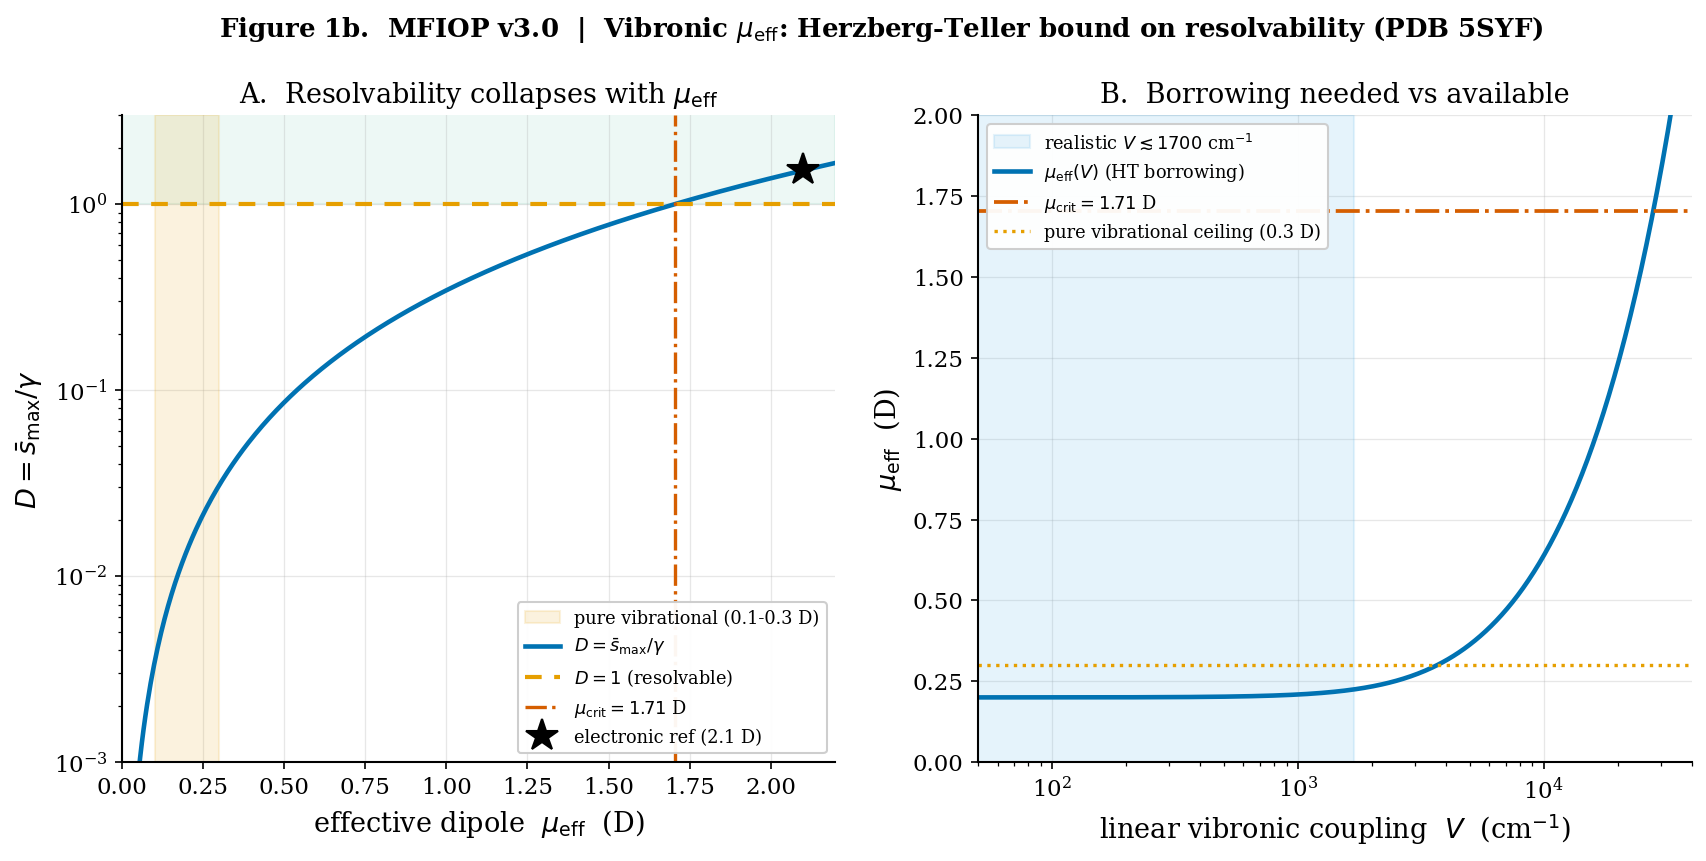

In [6]:

import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({'font.size':11,'font.family':'serif','axes.labelsize':13,
 'axes.titlesize':13,'legend.fontsize':9,'figure.dpi':150,'savefig.dpi':300,
 'savefig.bbox':'tight','axes.grid':True,'grid.alpha':0.30,'grid.linewidth':0.6,
 'axes.axisbelow':True,'lines.linewidth':2.2})
OB='#0072B2';OO='#E69F00';OT='#009E73';OV='#D55E00';OS='#56B4E9';OG='#999999'
def _dsp(a):a.spines['top'].set_visible(False);a.spines['right'].set_visible(False)

# --- Figure 1b (Okabe-Ito, restyled) ---
smax=8.05; mg=2.1; gr=5.31; dE=35700-1020
Dhom=lambda m: smax*(m/mg)**2/gr; mc=mg*np.sqrt(gr/smax)
fig,(a1,a2)=plt.subplots(1,2,figsize=(13.5,5.6))
fig.suptitle('Figure 1b.  MFIOP v3.0  |  Vibronic $\\mu_{\\mathrm{eff}}$: '
 'Herzberg-Teller bound on resolvability (PDB 5SYF)',fontsize=12.5,fontweight='bold',y=1.0)
mu=np.linspace(0.05,2.2,400)
a1.axvspan(0.1,0.3,color=OO,alpha=0.13,label='pure vibrational (0.1-0.3 D)')
a1.axhspan(1.0,1e2,color=OT,alpha=0.07,zorder=0)
a1.plot(mu,Dhom(mu),color=OB,label=r'$D=\bar{s}_{\max}/\gamma$')
a1.axhline(1.0,color=OO,ls=(0,(4,3)),lw=2.0,label=r'$D=1$ (resolvable)')
a1.axvline(mc,color=OV,ls='-.',lw=1.6,label=fr'$\mu_{{\mathrm{{crit}}}}={mc:.2f}$ D')
a1.plot(2.1,Dhom(2.1),'*',color='k',ms=16,zorder=6,label='electronic ref (2.1 D)')
a1.set_yscale('log');a1.set_xlim(0,2.2);a1.set_ylim(1e-3,3)
a1.set_xlabel(r'effective dipole  $\mu_{\mathrm{eff}}$  (D)');a1.set_ylabel(r'$D=\bar{s}_{\max}/\gamma$')
a1.set_title('A.  Resolvability collapses with $\\mu_{\\mathrm{eff}}$')
a1.legend(loc='lower right',framealpha=0.95,fontsize=8.5);_dsp(a1)
V=np.logspace(1.7,4.6,400);muC=0.2;mV=np.sqrt(muC**2+(mg*V/dE)**2)
a2.axvspan(50,1700,color=OS,alpha=0.15,label=r'realistic $V\lesssim1700$ cm$^{-1}$')
a2.plot(V,mV,color=OB,label=r'$\mu_{\mathrm{eff}}(V)$ (HT borrowing)')
a2.axhline(mc,color=OV,ls='-.',lw=1.8,label=fr'$\mu_{{\mathrm{{crit}}}}={mc:.2f}$ D')
a2.axhline(0.3,color=OO,ls=':',lw=1.6,label='pure vibrational ceiling (0.3 D)')
a2.set_xscale('log');a2.set_xlim(50,4e4);a2.set_ylim(0,2.0)
a2.set_xlabel(r'linear vibronic coupling  $V$  (cm$^{-1}$)');a2.set_ylabel(r'$\mu_{\mathrm{eff}}$  (D)')
a2.set_title('B.  Borrowing needed vs available')
a2.legend(loc='upper left',framealpha=0.95,fontsize=8.5);_dsp(a2)
plt.savefig('MFIOP_v2_fig01b_vibronic_mu_eff.png'); plt.show()


## 5. What a single-TRP QM/MM would have to deliver (Priority #1)

This notebook is a *bound*, not a substitute for the calculation the critique
asked for. To pin $\mu_{\mathrm{eff}}$ for real, a minimal TD-DFT / QM/MM job on
one tryptophan needs to report:

1. the ground-state normal mode nearest 1020 cm⁻¹ and its Condon IR dipole
   $\mu_{\mathrm C}=\partial\mu/\partial Q_k$;
2. the ¹Lₐ excitation energy and $\mu_{ge}$ at the equilibrium geometry
   (recovers $\Delta E_{ge}$, μ = 2.1 D);
3. the derivative $\partial E(^1L_a)/\partial Q_k$ → the HT coupling $V$
   (equivalently the Huang–Rhys $S$ from an excited-state gradient).

Plugging $(\mu_{\mathrm C}, V)$ into the cell below returns the one number the
whole resolvability claim rests on.


In [7]:
def resolvability_from_qmmm(mu_C_D, V_cm1, gamma=gamma_ref):
    k    = V_cm1/dE_ge
    meff = np.sqrt(mu_C_D**2 + (mu_ge*k)**2)
    r    = (s_max_ref/gamma)*(meff/mu_ge)**2
    verdict = 'RESOLVABLE' if r > 1 else 'irresolvable'
    print(f'mu_C={mu_C_D} D, V={V_cm1} cm^-1  ->  kappa={k:.3f}, '
          f'mu_eff={meff:.3f} D,  s_max/gamma={r:.3e}  [{verdict}]')
    return meff, r

# placeholder inputs — replace with QM/MM outputs
_ = resolvability_from_qmmm(mu_C_D=0.2, V_cm1=600)

mu_C=0.2 D, V=600 cm^-1  ->  kappa=0.017, mu_eff=0.203 D,  s_max/gamma=1.420e-02  [irresolvable]


## 6. Bottom line

- The resolvability claim $\bar s_{\max}/\gamma = 1.52$ holds **only** at the
  electronic dipole $\mu_{ge}=2.1$ D — the ¹Lₐ UV regime.
- Keeping it above 1 needs $\mu_{\mathrm{eff}}\ge 1.71$ D, i.e. borrowing ~81% of
  that electronic dipole into a 1020 cm⁻¹ vibration ($V$ approaching the
  electronic gap) — not physical for Herzberg–Teller.
- Realistic borrowing ($V\lesssim1700$ cm⁻¹, $\mu_{\mathrm{eff}}\lesssim0.3$ D)
  gives $\bar s_{\max}/\gamma \sim 10^{-2}$ — **irresolvable**, matching the
  reviewer's ~0.03.

The geometry result stands regardless; what this settles is whether the *spectral
feature* is observable in the IR window. A single-TRP QM/MM (Section 5) turns
this bound into a number.
